# Car–Cyclist Hazard Prediction with Neural Memory

Can a learned embedding improve nearest-neighbor retrieval for car–cyclist scenarios? I compare retrieval in the original feature space with retrieval in a learned embedding space, using a direct MLP classifier as a reference.

The data and hazard labels are synthetic. This is an independent experiment, not a validated traffic safety model or an Ericsson-affiliated project.

## 1. Setup

The experiment runs on CPU with a fixed random seed. Results may vary slightly across software versions.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import accuracy_score, f1_score

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)
rng = np.random.default_rng(SEED)

print(f"PyTorch version: {torch.__version__}")
print("Device: CPU (no GPU required)")

PyTorch version: 2.14.1+cpu
Device: CPU (no GPU required)


## 2. Synthetic traffic data

Each sample represents a static car–cyclist encounter.

| Feature | Range / values |
|---|---|
| `car_speed_kmh` | 15–85 km/h |
| `bicycle_distance_m` | 4–70 m |
| `cyclist_crossing` | 0 / 1 |
| `low_visibility` | 0 / 1 |
| `driver_distracted` | 0 / 1 |

Labels are sampled from a logistic rule using these features (`1` = hazard, `0` = safe). The distance-to-speed ratio is a simplified proxy for closing time, not a physical time-to-collision estimate. The stratified split leaves 400 of the 1,600 samples for testing.

In [2]:
N = 1600
car_speed = rng.uniform(15, 85, N)
bicycle_distance = rng.uniform(4, 70, N)
cyclist_crossing = rng.binomial(1, 0.46, N)
low_visibility = rng.binomial(1, 0.30, N)
driver_distracted = rng.binomial(1, 0.25, N)

FEATURE_NAMES = [
    "car_speed_kmh", "bicycle_distance_m", "cyclist_crossing",
    "low_visibility", "driver_distracted",
]
X = np.column_stack([
    car_speed, bicycle_distance, cyclist_crossing,
    low_visibility, driver_distracted,
]).astype("float32")

# Closing-time proxy used in the synthetic labeling rule.
time_to_close = bicycle_distance / (car_speed / 3.6)
logit = (
    -2.7
    + 2.2 * cyclist_crossing
    + 1.4 * np.clip(3.2 - time_to_close, -2, 3)
    + 0.7 * low_visibility
    + 0.7 * driver_distracted
)
synthetic_label_probability = 1 / (1 + np.exp(-logit))
y = rng.binomial(1, synthetic_label_probability).astype("float32")

# Keep the test split out of training and retrieval.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=SEED
)

# Fit the scaler on training data only.
scaler = StandardScaler().fit(X_train)
train = scaler.transform(X_train).astype("float32")
test = scaler.transform(X_test).astype("float32")

print(f"Historical training episodes: {len(X_train)}")
print(f"Unseen test episodes: {len(X_test)}")
print(f"Training hazard-label rate: {y_train.mean():.1%}")
display(pd.DataFrame(X_train[:5], columns=FEATURE_NAMES).assign(hazard_label=y_train[:5].astype(int)))

Historical training episodes: 1200
Unseen test episodes: 400
Training hazard-label rate: 40.6%


,car_speed_kmh,bicycle_distance_m,cyclist_crossing,low_visibility,driver_distracted,hazard_label
0,30.815027,44.744907,1.0,0.0,0.0,0
1,72.343994,59.513924,0.0,0.0,1.0,0
2,49.287697,57.977131,1.0,0.0,0.0,0
3,54.986286,26.014296,1.0,1.0,0.0,1
4,36.722656,45.042892,1.0,0.0,0.0,0


## 3. Raw-feature KNN

Retrieve the seven closest training samples using Euclidean distance on standardized features. The mean of their binary labels serves as the classification score.

In [3]:
K = 7
raw_knn = NearestNeighbors(n_neighbors=K, metric="euclidean").fit(train)
raw_distances, raw_ids = raw_knn.kneighbors(test)
raw_memory_risk = y_train[raw_ids].mean(axis=1)

print("Raw-feature KNN retrieval is ready.")
print("Example historical hazard-label fraction:", round(float(raw_memory_risk[0]), 3))

Raw-feature KNN retrieval is ready.
Example historical hazard-label fraction: 0.857


## 4. Contrastive learning

The encoder maps five input features to an L2-normalized, eight-dimensional embedding. Training uses pairs sampled by class: same-label pairs minimize squared distance, while different-label pairs are penalized when their distance falls below the margin of 1.0.

Label agreement is used as a proxy for similarity; it does not imply that two encounters share the same cause.

Step 100/350 | contrastive loss = 0.1731
Step 200/350 | contrastive loss = 0.1853
Step 300/350 | contrastive loss = 0.1717


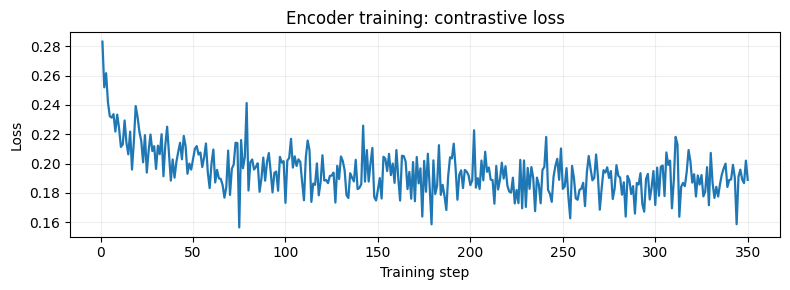

In [4]:
class SituationEncoder(nn.Module):
    """Convert 5 standardized traffic features into an 8-D unit embedding."""

    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(5, 16),
            nn.ReLU(),
            nn.Linear(16, 8),
        )

    def forward(self, x):
        return F.normalize(self.network(x), dim=-1)


encoder = SituationEncoder()
optimizer = torch.optim.Adam(encoder.parameters(), lr=0.005)
train_tensor = torch.tensor(train)

# Class-specific indices for pair sampling.
group_safe = np.flatnonzero(y_train == 0)
group_hazard = np.flatnonzero(y_train == 1)

losses = []
encoder.train()
for step in range(350):
    n_pairs = 256

    same_label = rng.integers(0, 2, n_pairs).astype("float32")
    first_label = rng.integers(0, 2, n_pairs)
    second_label = np.where(same_label == 1, first_label, 1 - first_label)

    ids1 = np.array([rng.choice(group_hazard if c else group_safe) for c in first_label])
    ids2 = np.array([rng.choice(group_hazard if c else group_safe) for c in second_label])

    embedding1 = encoder(train_tensor[ids1])
    embedding2 = encoder(train_tensor[ids2])
    distance = torch.linalg.vector_norm(embedding1 - embedding2, dim=1)

    target = torch.tensor(same_label)
    margin = 1.0
    # Squared contrastive loss with a margin for negative pairs.
    loss = (
        target * distance.pow(2)
        + (1 - target) * torch.clamp(margin - distance, min=0).pow(2)
    ).mean()

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    losses.append(loss.item())

    if (step + 1) % 100 == 0:
        print(f"Step {step + 1:3d}/350 | contrastive loss = {loss.item():.4f}")

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(np.arange(1, len(losses) + 1), losses, linewidth=1.6)
ax.set(title="Encoder training: contrastive loss", xlabel="Training step", ylabel="Loss")
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

### Embedding-based retrieval

Use the same KNN configuration as the raw-feature baseline, changing only the representation used for retrieval.

In [5]:
encoder.eval()
with torch.no_grad():
    train_embeddings = encoder(torch.tensor(train)).numpy()
    test_embeddings = encoder(torch.tensor(test)).numpy()

learned_knn = NearestNeighbors(n_neighbors=K, metric="euclidean").fit(train_embeddings)
learned_distances, learned_ids = learned_knn.kneighbors(test_embeddings)
learned_memory_risk = y_train[learned_ids].mean(axis=1)

print("Learned embedding retrieval is ready.")
print("Embedding shape:", train_embeddings.shape)
print("Example raw KNN episode IDs:", raw_ids[0][:3].tolist())
print("Example neural KNN episode IDs:", learned_ids[0][:3].tolist())

Learned embedding retrieval is ready.
Embedding shape: (1200, 8)
Example raw KNN episode IDs: [695, 503, 1094]
Example neural KNN episode IDs: [695, 503, 1094]


## 5. Direct MLP classifier

Train a separate classifier on the standardized features using binary cross-entropy with logits. This baseline does not use retrieved samples at inference time.

In [6]:
classifier = nn.Sequential(
    nn.Linear(5, 16), nn.ReLU(),
    nn.Linear(16, 8), nn.ReLU(),
    nn.Linear(8, 1),
)
classifier_optimizer = torch.optim.Adam(classifier.parameters(), lr=0.01)
x_train_tensor = torch.tensor(train)
y_train_tensor = torch.tensor(y_train).unsqueeze(1)

classifier.train()
for epoch in range(120):
    logits = classifier(x_train_tensor)
    classification_loss = F.binary_cross_entropy_with_logits(logits, y_train_tensor)

    classifier_optimizer.zero_grad()
    classification_loss.backward()
    classifier_optimizer.step()

classifier.eval()
with torch.no_grad():
    mlp_risk = torch.sigmoid(classifier(torch.tensor(test))).squeeze(1).numpy()

print(f"MLP finished training | final training loss = {classification_loss.item():.4f}")

MLP finished training | final training loss = 0.3643


## 6. Test-set comparison

Compare accuracy and hazard-class F1 on the same held-out split. All methods use a decision threshold of 0.5. The majority-class baseline provides a reference for class imbalance.

Performance on 400 unseen synthetic episodes


,Accuracy,F1 (hazard)
Majority class,0.595,0.000
Raw-feature KNN,0.790,0.747
Neural-embedding KNN,0.782,0.737
Direct PyTorch MLP,0.810,0.768


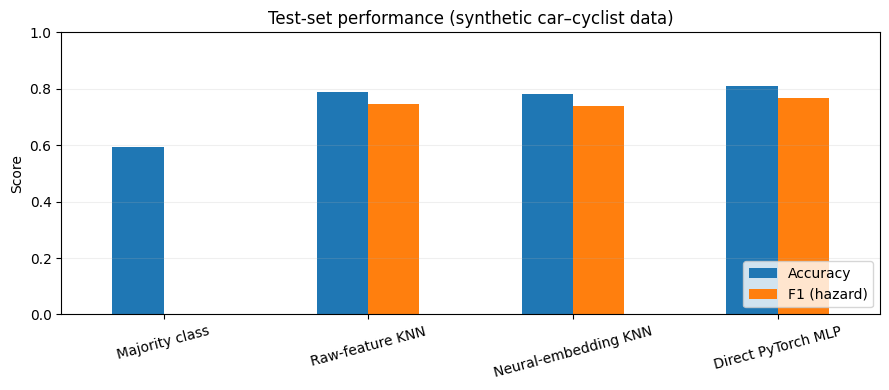

In [7]:
def evaluate(probability_estimates):
    predicted_labels = (np.asarray(probability_estimates) >= 0.5).astype(int)
    return {
        "Accuracy": accuracy_score(y_test.astype(int), predicted_labels),
        "F1 (hazard)": f1_score(y_test.astype(int), predicted_labels, zero_division=0),
    }

methods = {
    "Majority class": np.full_like(y_test, y_train.mean()),
    "Raw-feature KNN": raw_memory_risk,
    "Neural-embedding KNN": learned_memory_risk,
    "Direct PyTorch MLP": mlp_risk,
}
metrics = pd.DataFrame({name: evaluate(values) for name, values in methods.items()}).T
print("Performance on 400 unseen synthetic episodes")
display(metrics.round(3))

fig, ax = plt.subplots(figsize=(9, 4))
metrics.plot(kind="bar", ylim=(0, 1), rot=15, ax=ax)
ax.set(title="Test-set performance (synthetic car–cyclist data)", ylabel="Score", xlabel="")
ax.legend(loc="lower right")
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

### Results

Raw-feature KNN achieved 79.0% accuracy (F1 = 0.747), compared with 78.2% (F1 = 0.737) for embedding-based KNN. The direct MLP performed best in this run, at 81.0% accuracy (F1 = 0.768).

Learning the embedding did not improve retrieval-based classification. One possible explanation is that the original five features already capture much of the structure of the synthetic labeling rule. Repeated runs would be needed to assess whether the observed differences are consistent.

## 7. Retrieved examples

Inspect a fixed test sample and its three nearest training examples in embedding space. The retrieval scores describe the fraction of hazard labels among neighbors, not calibrated accident probabilities.

In [8]:
example_index = 2  # Fixed test sample for comparison.

print("Current unseen car–cyclist situation:")
display(pd.DataFrame([X_test[example_index]], columns=FEATURE_NAMES).round(2))

summary = pd.DataFrame({
    "Item": ["Synthetic ground-truth label", "Direct MLP output",
             "Raw KNN hazard-label fraction", "Neural KNN hazard-label fraction"],
    "Value": [
        "Hazard" if y_test[example_index] else "Safe",
        f"{mlp_risk[example_index]:.1%}",
        f"{raw_memory_risk[example_index]:.1%}",
        f"{learned_memory_risk[example_index]:.1%}",
    ],
})
display(summary)

memory_indices = learned_ids[example_index][:3]
remembered = pd.DataFrame(X_train[memory_indices], columns=FEATURE_NAMES)
remembered.insert(0, "rank", np.arange(1, len(memory_indices) + 1))
remembered["historical_hazard_label"] = y_train[memory_indices].astype(int)
print("Three nearest historical episodes in the learned embedding space:")
display(remembered.round(2))

Current unseen car–cyclist situation:


,car_speed_kmh,bicycle_distance_m,cyclist_crossing,low_visibility,driver_distracted
0,68.089996,42.779999,0.0,0.0,0.0


,Item,Value
0,Synthetic ground-truth label,Safe
1,Direct MLP output,20.0%
2,Raw KNN hazard-label fraction,14.3%
3,Neural KNN hazard-label fraction,0.0%


Three nearest historical episodes in the learned embedding space:


,rank,car_speed_kmh,bicycle_distance_m,cyclist_crossing,low_visibility,driver_distracted,historical_hazard_label
0,1,69.419998,44.279999,0.0,0.0,0.0,0
1,2,64.570000,40.650002,0.0,0.0,0.0,0
2,3,69.529999,42.389999,0.0,0.0,0.0,0


## 8. Discussion and next steps

The experiment compares two ways of retrieving examples, rather than testing a memory-augmented predictor. The MLP and retrieval models operate independently The main limitation is the dataset: static synthetic snapshots omit cyclist motion, braking, road geometry and other temporal information. The reported scores cannot establish real-world safety performance.

A useful next step is to repeat the comparison across random seeds and embedding sizes. With trajectory data, similarity could also incorporate interaction dynamics rather than label agreement alone. A separate ablation with and without retrieved information would then test whether retrieval improves prediction.